# PHREEQC databases and your own data

Every equilibrium calculation needs thermodynamic data: the species that exist, the equilibrium constant $\log K$ of each reaction, and the parameters of the activity model. This notebook shows how to:

1. load one of the five bundled PHREEQC databases and build a system from it;
2. change a constant or an activity parameter from a database, or add species and reactions to it;
3. declare your own species, reactions and activity model in Python;
4. write a small database of your own in PHREEQC format;
5. describe all of this in a YAML specification;
6. choose an activity model by solving one problem with two databases.

**Prerequisites.** Read notebook 01 first; it introduces `System`, `equilibrate` and the result object. Notebook 04 covers one more source of data: estimating constants from measurements.

**Units and conventions.** Amounts are in mol. Concentrations are molalities, mol per kg of water (written m). $\log K$ is base 10, for the reaction as written, at 25 °C unless a temperature expression is given.

Reference documentation: [`docs/databases.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/databases.md) and [`docs/custom-data.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/custom-data.md).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import yaml
from discopt.speciation import (PhreeqcDatabase, available_databases, System, SIT, from_yaml, solve_spec, plot)

for name in available_databases():
    d = PhreeqcDatabase.load(name)
    print(f"{name:16s} {len(d.species):5d} aqueous species {len(d.phases):5d} phases  "
          f"default activity model: {type(d.default_activity()).__name__}")

llnl.dat          1327 aqueous species  1215 phases  default activity model: LLNL
phreeqc.dat        231 aqueous species    71 phases  default activity model: TruesdellJones
pitzer.dat          37 aqueous species    72 phases  default activity model: Pitzer
sit.dat           1526 aqueous species   924 phases  default activity model: SIT
wateq4f_PWN.dat    384 aqueous species   325 phases  default activity model: TruesdellJones


## 1. A bundled database

A PHREEQC database is a text file of species, reactions and phases with their constants (Parkhurst and Appelo 2013, [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)). The five bundled files, and the activity model each one selects, are listed above. Below, $I = \tfrac12\sum_i m_i z_i^2$ is the ionic strength.

| file | activity model | typical use |
|------|----------------|-------------|
| [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) | Truesdell-Jones | fresh and brackish water, I ≲ 1 m |
| [`pitzer.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/pitzer.dat) | Pitzer | brines and evaporites |
| [`wateq4f_PWN.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/wateq4f_PWN.dat) | Truesdell-Jones | natural waters, trace metals |
| [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) | B-dot | many elements including rare earths, 0–300 °C |
| [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) | SIT | ThermoChimie: actinides, radioactive waste |

Sources, provenance and terms of use are in [`docs/databases.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/databases.md) and the References at the end.

Parsing gives plain Python objects. Each species and phase keeps its reaction, `log_k`, `delta_h`, `-analytic` coefficients and `-gamma` parameters.

In [2]:
db = PhreeqcDatabase.load("phreeqc.dat")
print(len(db.masters), "master species,", len(db.species), "aqueous species,", len(db.phases), "phases")
for name in ["Calcite", "Aragonite", "CO2(g)"]:
    e = db.phases[name]
    print(f"{name:10s} {e.nu}\n{'':10s} log_k={e.logK}  delta_h={e.dH:.4g} J/mol  analytic={e.analytic}")
db.species["CaHCO3+"]

50 master species, 231 aqueous species, 71 phases
Calcite    {'CO3-2': 1.0, 'Ca+2': 1.0, 'Calcite': -1.0}
           log_k=-8.48  delta_h=-9611 J/mol  analytic=(-171.9065, -0.077993, 2839.319, 71.595)
Aragonite  {'CO3-2': 1.0, 'Ca+2': 1.0, 'Aragonite': -1.0}
           log_k=-8.336  delta_h=-1.083e+04 J/mol  analytic=(-171.9773, -0.077993, 2903.293, 71.595)
CO2(g)     {'CO2': 1.0, 'CO2(g)': -1.0}
           log_k=-1.468  delta_h=-1.998e+04 J/mol  analytic=(10.5624, -0.023547, -3972.8, 0.0, 587460.0, 1.9194e-05)


Entry(name='CaHCO3+', nu={'Ca+2': -1.0, 'CO3-2': -1.0, 'H+': -1.0, 'CaHCO3+': 1.0}, logK=11.435, dH=-3644.264, analytic=(1317.0071, 0.34546894, -39916.84, -517.70761, 563713.9), a0=6.0, b=0.0, gas=False, options={'dw': ['5.06e-10'], 'vm': ['3.1911', '.0104', '5.7459', '-2.7794', '.3084', '5.4']})

**Reading the output.** [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) has 50 master species, 231 aqueous species and 71 phases.

- `nu` holds stoichiometric coefficients: negative for reactants, positive for products. Calcite dissolves as Calcite = Ca²⁺ + CO₃²⁻.
- `log_k` is $\log_{10} K$ at 25 °C for that reaction; for calcite $K_{sp} = 10^{-8.48}$.
- `delta_h` is the reaction enthalpy, converted to J/mol.
- `analytic` holds coefficients of a $\log K(T)$ expression. When present, it takes precedence over `log_k` and `delta_h`, as in PHREEQC.
- Aqueous species such as CaHCO₃⁺ are formation reactions from master species; `a0` (ion size, Å) and `b` are their Truesdell-Jones parameters.

**Building a system.** `db.system(components, phases=...)` builds a `System` containing every species that the requested elements, or valence states such as `"C(4)"` (carbonate carbon), allow. The `phases` are *candidates*: each is present only if the solution becomes saturated with it.

The example is calcite and aragonite, two polymorphs of CaCO₃, in water open to atmospheric CO₂:
- `{"Calcite": 1.0}` adds 1 mol of calcite to 1 kg of water;
- `fixed={"CO2(g)": -3.4}` fixes $\log_{10} P_{\mathrm{CO_2}} = -3.4$ (atm), close to the atmospheric value.

Only calcite should remain, because aragonite is the metastable polymorph.

In [3]:
s = db.system(["Ca", "C(4)"], phases=["Calcite", "Aragonite", "CO2(g)"])
print(len(s.species), "species:", ", ".join(sp.name for sp in s.species))
r = s.equilibrate({"Calcite": 1.0}, fixed={"CO2(g)": -3.4})
print(r.summary())

14 species: H+, H2O, Ca+2, CO3-2, OH-, HCO3-, CO2, (CO2)2, CaOH+, CaCO3, CaHCO3+, Calcite, Aragonite, CO2(g)


converged=True method=complementarity I=0.00158 pH=8.2137 charge_imbalance=1.08e-19 water=0.999991 kg
aqueous                   molality     log10 a
H+                    6.373880e-09     -8.2137
Ca+2                  5.217384e-04     -3.3584
CO3-2                 9.001746e-06     -5.1214
OH-                   1.731252e-06     -5.7810
HCO3-                 1.029514e-03     -3.0063
CO2                   1.354178e-05     -4.8682
(CO2)2                3.367197e-12    -11.4726
CaOH+                 1.243294e-08     -7.9247
CaCO3                 5.562827e-06     -5.2545
CaHCO3+               5.752869e-06     -5.2589
solid                       amount          SI
Calcite               9.994669e-01     -0.0000
Aragonite             0.000000e+00     -0.1438
gas                         amount     log10 P
CO2(g)                       fixed     -3.4000
residuals: balance=2.5e-19, mass_action=1.8e-15, complementarity=0.0e+00, ionic_strength=4.5e-15


**Result.** The solution reaches pH 8.21 and 0.9995 mol of calcite remains. The `SI` column is the saturation index, $\mathrm{SI} = \log_{10}(\mathrm{IAP}/K)$, where IAP is the ion activity product: SI = 0 at saturation, SI < 0 when undersaturated. Calcite has SI = 0 and aragonite SI = −0.144, so aragonite is correctly absent.

This is *complementarity*: for each solid, either its amount is zero or its SI is zero. The `residuals` line shows that mass balance, mass action and complementarity hold to round-off.

**Metastable equilibrium.** To compute the equilibrium with aragonite, for example to interpret a precipitate that has not yet converted to calcite, remove the stable phase with `suppress=["Calcite"]`. The helper `dissolved_ca` sums the molalities of all calcium species.

In [4]:
def dissolved_ca(res):
    return sum(v for k, v in res.molality.items() if k.startswith("Ca"))

meta = s.equilibrate({"Aragonite": 1.0}, fixed={"CO2(g)": -3.4}, suppress=["Calcite"])
print(f"stable:     present={r.present}  Ca={dissolved_ca(r):.4e} m  SI(Aragonite)={r.SI['Aragonite']:+.3f}")
print(f"metastable: present={meta.present}  Ca={dissolved_ca(meta):.4e} m")

stable:     present=['Calcite']  Ca=5.3307e-04 m  SI(Aragonite)=-0.144
metastable: present=['Aragonite']  Ca=6.0103e-04 m


**Result.** With calcite suppressed, aragonite is saturated and dissolved calcium rises from 5.33 × 10⁻⁴ to 6.01 × 10⁻⁴ m, as expected for the more soluble polymorph.

## 2. Changing and extending database values

Every reaction in the system is a `Reaction` named after its database species or phase. Its constants are ordinary attributes that you can change.

**Precedence.** An `analytic` expression takes precedence over `logK`/`dH`. To use your own 25 °C value, set `analytic = None` first; otherwise your `logK` is ignored.

The cell below tries two values of the calcite constant, then restores the database values so later cells are unaffected.

In [5]:
calcite = next(rx for rx in s.reactions if rx.name == "Calcite")
print(calcite.equation(), "| logK(25 C) from analytic:", round(calcite.logK_at(298.15), 4))
saved = (calcite.logK, calcite.dH, calcite.analytic)

calcite.analytic, calcite.logK = None, -8.40        # e.g. your own measured value
r2 = s.equilibrate({"Calcite": 1.0}, fixed={"CO2(g)": -3.4})
print(f"logK -8.40: present={r2.present}, dissolved Ca {dissolved_ca(r):.4e} -> {dissolved_ca(r2):.4e} m")

calcite.logK = -8.30                                 # now less stable than aragonite (logK -8.336)
r3 = s.equilibrate({"Calcite": 1.0}, fixed={"CO2(g)": -3.4})
print(f"logK -8.30: present={r3.present}, dissolved Ca {dissolved_ca(r3):.4e} m (set by aragonite)")

calcite.logK, calcite.dH, calcite.analytic = saved   # restore

Calcite = CO3-2 + Ca+2 | logK(25 C) from analytic: -8.4798


logK -8.40: present=['Calcite'], dissolved Ca 5.3307e-04 -> 5.6972e-04 m


logK -8.30: present=['Aragonite'], dissolved Ca 6.0103e-04 m (set by aragonite)


**Result.**
- With $\log K = -8.40$, calcite is more soluble than with the database value (−8.48) but still controls the solution; dissolved calcium rises from 5.33 × 10⁻⁴ to 5.70 × 10⁻⁴ m.
- With $\log K = -8.30$, calcite is more soluble than aragonite ($\log K = -8.336$). The calculation precipitates aragonite instead, and dissolved calcium is 6.01 × 10⁻⁴ m, the metastable aragonite value found above.

Changing one constant can change which phase is stable, and complementarity handles that without any change to the problem set-up.

**Adding a species.** [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) has no CaCl⁺ complex. The cell below adds one, with an illustrative constant, to gypsum (CaSO₄·2H₂O) in 0.5 m NaCl. A new species needs two calls: `aqueous` declares it with its activity parameters, and `reaction` links it to existing species.

**Activity parameters.** Per-species activity parameters live in `species.params`, a dict you can edit. The second part of the cell changes the Truesdell-Jones ion size `a0` of Ca²⁺, then restores it.

In [6]:
g = db.system(["Ca", "S(6)", "Na", "Cl"], phases=["Gypsum"])
brine = {"Gypsum": 1.0, "Na": 0.5, "Cl": 0.5}                 # gypsum in 0.5 m NaCl
before = g.equilibrate(brine)
print("CaCl+ in database system:", "CaCl+" in g)

g.aqueous("CaCl+", a0=5.0, b=0.0)
g.reaction("Ca+2 + Cl- = CaCl+", logK=0.4, name="CaCl+")     # illustrative value
after = g.equilibrate(brine)
print(f"add CaCl+: dissolved Ca {dissolved_ca(before):.4e} -> {dissolved_ca(after):.4e} m; "
      f"CaCl+ = {after.molality['CaCl+']:.3e} m")

print("Ca+2 params:", g["Ca+2"].params)
g["Ca+2"].params["a0"] = 6.0                                  # illustrative: larger ion size
bigger = g.equilibrate(brine)
g["Ca+2"].params["a0"] = 5.0                                  # restore
print(f"a0 5 -> 6: gamma(Ca+2) {after.gamma['Ca+2']:.4f} -> {bigger.gamma['Ca+2']:.4f}, "
      f"dissolved Ca {dissolved_ca(after):.4e} -> {dissolved_ca(bigger):.4e} m")

CaCl+ in database system: False
add CaCl+: dissolved Ca 3.3170e-02 -> 3.7170e-02 m; CaCl+ = 7.570e-03 m
Ca+2 params: {'a0': 5.0, 'b': 0.165}
a0 5 -> 6: gamma(Ca+2) 0.2536 -> 0.2980, dissolved Ca 3.7170e-02 -> 3.5170e-02 m


**Result.**
- Adding CaCl⁺ raises dissolved calcium from 0.0332 to 0.0372 m: the complex takes up free Ca²⁺, so more gypsum dissolves before saturation.
- A larger `a0` raises γ(Ca²⁺) from 0.254 to 0.298, so gypsum saturates sooner and dissolved calcium falls to 0.0352 m.

## 3. Your own system, with your own activity model

**Declaring species.**
- A species' charge is read from its name.
- Truesdell-Jones and B-dot take per-species `a0` and `b`.
- SIT takes ion-pair interaction coefficients $\varepsilon_{ij}$ (kg/mol).
- Pitzer takes a `PitzerParameters` table.

**Declaring reactions.** Each reaction takes `logK` at 25 °C and, optionally, `dH` (J/mol), `dCp`, `dV` or `analytic` for temperature and pressure dependence.

The cell below builds a system from scratch: NaCl solutions with halite (NaCl(s)) as the candidate solid, using the specific ion interaction theory, SIT (Guggenheim and Turgeon 1955, [doi:10.1039/TF9555100747](https://doi.org/10.1039/TF9555100747), in the NEA form of Grenthe et al. 1992). SIT adds a term $\varepsilon_{ij} m_j$ for each oppositely charged ion to the Debye–Hückel term. Increasing amounts of halite are added to 1 kg of water.

In [7]:
nacl = System("NaCl with SIT", activity=SIT(eps={("Na+", "Cl-"): 0.03}))
nacl.aqueous("Na+")
nacl.aqueous("Cl-")
nacl.solid("Halite")
nacl.reaction("Halite = Na+ + Cl-", logK=1.570, dH=3841.0, name="Halite")
for m in [0.1, 1.0, 3.0, 8.0]:
    res = nacl.equilibrate({"Halite": m})
    print(f"NaCl added {m:4.1f} m: gamma(Na+)={res.gamma['Na+']:.3f}  dissolved={res.molality['Na+']:.3f} m  present={res.present}")

NaCl added  0.1 m: gamma(Na+)=0.783  dissolved=0.100 m  present=[]
NaCl added  1.0 m: gamma(Na+)=0.670  dissolved=1.000 m  present=[]
NaCl added  3.0 m: gamma(Na+)=0.699  dissolved=3.000 m  present=[]


NaCl added  8.0 m: gamma(Na+)=0.869  dissolved=7.017 m  present=['Halite']


**Result.** Up to 3 m all the halite dissolves (`present=[]`, no solid). γ(Na⁺) falls from 0.783 at 0.1 m to 0.670 at 1 m, then rises to 0.699 at 3 m as the ε term grows with molality. At 8 m the solution saturates: halite is present with 7.02 m dissolved. That point is beyond the usual SIT range (about 3–4 m), so with a single ε value it is an illustration, not a prediction of halite solubility.

## 4. A database file of your own

Any PHREEQC-format text works, from a full database to a handful of species. `delta_h` is in kJ/mol unless it is followed by `kcal`.

In [8]:
MINI = '''
SOLUTION_MASTER_SPECIES
H       H+      -1.0    H       1.008
H(1)    H+      -1.0    0
E       e-      0       0.0     0
O       H2O     0       O       16.0
O(-2)   H2O     0       0
Ca      Ca+2    0       Ca      40.08
S       SO4-2   0       SO4     32.064
S(6)    SO4-2   0       SO4
SOLUTION_SPECIES
H+ = H+
    log_k 0
e- = e-
    log_k 0
H2O = H2O
    log_k 0
Ca+2 = Ca+2
    log_k 0
    -gamma 5.0 0.165
SO4-2 = SO4-2
    log_k 0
    -gamma 5.0 -0.04
H2O = OH- + H+
    log_k -14.0
    delta_h 13.362 kcal
Ca+2 + SO4-2 = CaSO4
    log_k 2.25
    delta_h 1.325 kcal
PHASES
Gypsum
    CaSO4:2H2O = Ca+2 + SO4-2 + 2 H2O
    log_k -4.58
    delta_h -0.109 kcal
END
'''
mine = PhreeqcDatabase(MINI)          # or PhreeqcDatabase.from_file("mine.dat")
mini = mine.system(["Ca", "S(6)"], phases=["Gypsum"])
full = db.system(["Ca", "S(6)"], phases=["Gypsum"])
for label, sysm in [("mini database", mini), ("phreeqc.dat", full)]:
    res = sysm.equilibrate({"Gypsum": 1.0})
    print(f"{label:14s} gypsum solubility {dissolved_ca(res):.5f} m, pH {res.pH:.3f}, species: {sorted(res.molality)}")

mini database  gypsum solubility 0.01511 m, pH 7.000, species: ['Ca+2', 'CaSO4', 'H+', 'OH-', 'SO4-2']


phreeqc.dat    gypsum solubility 0.01508 m, pH 7.064, species: ['Ca+2', 'CaHSO4+', 'CaOH+', 'CaSO4', 'H+', 'HSO4-', 'OH-', 'SO4-2']


**Result.** The five-species file gives a gypsum solubility of 0.01511 m, against 0.01508 m from [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat). Its pH is exactly 7.000 because it has no HSO₄⁻ or CaOH⁺, so dissolving gypsum neither consumes nor releases H⁺; [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) gives pH 7.064. A small database can reproduce the main quantity, but only the species it contains can appear in the result.

## 5. Everything as a YAML specification

A specification can start from a database, override constants, and add species and reactions. The schema is strict, so a misspelled key is an error. `solve_spec` returns a JSON-serializable dict, and `System.to_spec()` writes any system back out as explicit data.

In [9]:
spec = yaml.safe_load('''
name: gypsum in brine
database: {file: phreeqc.dat, components: [Ca, "S(6)", Na, Cl], phases: [Gypsum]}
overrides:
  Gypsum: {logK: -4.50}
species:
  - {name: CaCl+, a0: 5.0}
reactions:
  - {equation: "Ca+2 + Cl- = CaCl+", logK: 0.4, name: CaCl+}
problem:
  amounts: {Gypsum: 1.0, Na: 0.5, Cl: 0.5}
''')
out = solve_spec(spec)
print(out["converged"], out["present"], {k: f"{v:.3e}" for k, v in out["molality"].items() if k.startswith("Ca")})

explicit = from_yaml(spec).to_spec()
print("explicit spec sections:", list(explicit), "|", len(explicit["species"]), "species,", len(explicit["reactions"]), "reactions")

True ['Gypsum'] {'Ca+2': '2.796e-02', 'CaOH+': '1.649e-08', 'CaSO4': '5.074e-03', 'CaHSO4+': '4.890e-09', 'CaCl+': '8.306e-03'}
explicit spec sections: ['name', 'temperature', 'activity', 'species', 'reactions', 'masters'] | 15 species, 9 reactions


**Result.** The specification repeats the CaCl⁺ example of Section 2 with the gypsum constant raised from −4.58 to −4.50. Gypsum is present and total dissolved calcium (Ca²⁺ + CaSO₄ + CaCl⁺) is 0.0413 m, up from 0.0372 m with the database constant. `to_spec()` writes the whole system as explicit data (15 species, 9 reactions) with no reference to [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat), which keeps a calculation reproducible if the database changes.

## 6. Choosing an activity model: gypsum in NaCl brines

The activity $a_i = \gamma_i m_i$ is the effective concentration that enters mass action. The activity model computes the activity coefficients $\gamma_i$, and matters most in concentrated solutions. The same question can be answered with two databases:

- [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) with Truesdell-Jones (Truesdell and Jones 1974, [pubs.usgs.gov/publication/70232379](https://pubs.usgs.gov/publication/70232379)), an ion-association model intended for I ≲ 1 m;
- [`pitzer.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/pitzer.dat) with Pitzer's specific-interaction model (Pitzer 1973, [doi:10.1021/j100621a026](https://doi.org/10.1021/j100621a026); database of Plummer et al. 1988, [doi:10.3133/wri884153](https://doi.org/10.3133/wri884153)), intended for brines.

The two agree in dilute solution and diverge as the NaCl concentration grows. Which curve to trust follows from the range each model was parameterized for, not from which one is "more accurate" in general.

phreeqc.dat (Truesdell-Jones) converged: True | dissolved Ca (m): [0.016  0.0269 0.0332 0.0413 0.051  0.0569 0.0607 0.0634]


 INFO pounce::linesearch: theta_max raised 3.734e4 -> 3.734e6 (raise 1 of 4): 3 consecutive line searches had every trial rejected at the theta_max gate (pounce#546)


pitzer.dat (Pitzer) converged: True | dissolved Ca (m): [0.016  0.0282 0.0356 0.0454 0.0552 0.0577 0.0559 0.052 ]


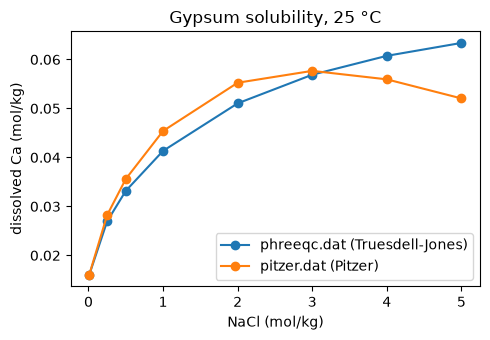

In [10]:
pz = PhreeqcDatabase.load("pitzer.dat")
systems = {"phreeqc.dat (Truesdell-Jones)": db.system(["Ca", "S(6)", "Na", "Cl"], phases=["Gypsum"]),
           "pitzer.dat (Pitzer)": pz.system(["Ca", "S(6)", "Na", "Cl"], phases=["Gypsum"])}
nacl_m = np.array([0.01, 0.25, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0])
fig, ax = plt.subplots(figsize=(5, 3.5))
for label, sysm in systems.items():
    sw = plot.sweep(sysm, lambda m: {"amounts": {"Gypsum": 1.0, "Na": m, "Cl": m}}, nacl_m)
    ca = sw.get(dissolved_ca)
    print(label, "converged:", sw.converged.all(), "| dissolved Ca (m):", np.round(ca, 4))
    ax.plot(nacl_m, ca, "o-", label=label)
ax.set(xlabel="NaCl (mol/kg)", ylabel="dissolved Ca (mol/kg)", title="Gypsum solubility, 25 °C")
ax.legend()
plt.tight_layout()

**Result.** Both models give 0.016 m in nearly pure water, and solubility rises steeply as NaCl is added. At 1 m NaCl Pitzer gives 0.0454 m and Truesdell-Jones 0.0413 m; at 3 m both give about 0.057 m. Above 3 m they diverge: Pitzer has a maximum at 3 m and falls to 0.0520 m at 5 m, while Truesdell-Jones keeps rising to 0.0634 m, outside the range it was parameterized for.

**Changing Pitzer parameters.** The Pitzer parameters are a `PitzerParameters` table on the system's activity model. You can change or add entries with `add(kind, species, coefficients)`. The coefficients are PHREEQC's six temperature terms, or a single number.

In [11]:
gp = systems["pitzer.dat (Pitzer)"]
table = gp.activity.params                     # PitzerParameters of this system
# pair keys are unordered: find the Na+/Cl- entry of B0 (beta0)
key = next(k for k in table.data["B0"] if set(k) == {"Na+", "Cl-"})
original = table.data["B0"][key]               # six temperature coefficients
brine3 = {"Gypsum": 1.0, "Na": 3.0, "Cl": 3.0}  # gypsum in 3 m NaCl
base = gp.equilibrate(brine3)
table.add("B0", list(key), [original[0] + 0.01, *original[1:]])   # raise the 25 °C term by 0.01
changed = gp.equilibrate(brine3)
table.data["B0"][key] = original               # restore
print(f"B0(NaCl) {original[0]:.4f} -> {original[0] + 0.01:.4f}: gamma(Ca+2) {base.gamma['Ca+2']:.4f} -> {changed.gamma['Ca+2']:.4f}, "
      f"dissolved Ca {dissolved_ca(base):.4e} -> {dissolved_ca(changed):.4e}")

B0(NaCl) 0.0753 -> 0.0853: gamma(Ca+2) 0.5397 -> 0.6082, dissolved Ca 5.7674e-02 -> 5.7876e-02


**Result.** Raising $\beta^{(0)}$ for Na⁺–Cl⁻ from 0.0753 to 0.0853 raises γ(Ca²⁺) in 3 m NaCl from 0.540 to 0.608, but dissolved calcium changes by only 0.35 % (0.05767 to 0.05788 m). A single activity coefficient can be sensitive to a parameter that the solubility hardly depends on; notebook 04 shows how to find which parameters data can determine.

## Summary

- `PhreeqcDatabase.load(name)` parses a bundled database; `db.system(components, phases=...)` builds a system with the activity model that the file defines.
- Database constants are ordinary attributes. Clear `analytic` before setting your own `logK`. Add species with `aqueous` plus `reaction`; edit activity parameters through `species.params` or the Pitzer table.
- The same data can come from Python, a PHREEQC-format string or file, or a strict YAML specification; `to_spec()` exports any system as explicit data.
- Choose the database, and with it the activity model, to match the ionic strength of your problem.

**Next steps.** Notebook 04 fits constants and activity parameters to measurements; notebook 05 draws diagrams; notebook 06 uses [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) and [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat) for rare earths and thorium. Reference pages: [`docs/databases.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/databases.md), [`docs/custom-data.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/custom-data.md), [`docs/activity-models.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/activity-models.md).

## References

- Parkhurst, D.L., and Appelo, C.A.J. (2013). Description of input and examples for PHREEQC version 3. USGS Techniques and Methods 6-A43. [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)
- Plummer, L.N., Parkhurst, D.L., Fleming, G.W., and Dunkle, S.A. (1988). A computer program incorporating Pitzer's equations for calculation of geochemical reactions in brines. USGS WRI Report 88-4153. [doi:10.3133/wri884153](https://doi.org/10.3133/wri884153)
- Appelo, C.A.J. (2015). Principles, caveats and improvements in databases for calculating hydrogeochemical reactions in saline waters from 0 to 200 °C and 1 to 1000 atm. *Applied Geochemistry* 55, 62–71. [doi:10.1016/j.apgeochem.2014.11.007](https://doi.org/10.1016/j.apgeochem.2014.11.007)
- Ball, J.W., and Nordstrom, D.K. (1991). User's manual for WATEQ4F. USGS Open-File Report 91-183. [doi:10.3133/ofr91183](https://doi.org/10.3133/ofr91183)
- Delany, J.M., and Lundeen, S.R. (1991). The LLNL thermochemical data base. LLNL UCID-21658. <https://www.osti.gov/biblio/138193>
- Giffaut, E., et al. (2014). Andra thermodynamic database for performance assessment: ThermoChimie. *Applied Geochemistry* 49, 225–236. [doi:10.1016/j.apgeochem.2014.05.007](https://doi.org/10.1016/j.apgeochem.2014.05.007)
- Truesdell, A.H., and Jones, B.F. (1974). WATEQ, a computer program for calculating chemical equilibria of natural waters. *J. Res. U.S. Geol. Survey* 2(2), 233–248. <https://pubs.usgs.gov/publication/70232379>
- Pitzer, K.S. (1973). Thermodynamics of electrolytes. I. Theoretical basis and general equations. *J. Phys. Chem.* 77, 268–277. [doi:10.1021/j100621a026](https://doi.org/10.1021/j100621a026)
- Guggenheim, E.A., and Turgeon, J.C. (1955). Specific interaction of ions. *Trans. Faraday Soc.* 51, 747. [doi:10.1039/TF9555100747](https://doi.org/10.1039/TF9555100747)
- Grenthe, I., et al. (1992). *Chemical Thermodynamics of Uranium.* NEA-OECD, North-Holland. <https://www.oecd-nea.org/jcms/pl_13704>

Full bibliography: [`docs/references.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/references.md).